# Modelling and evaluation

This section trains three classifiers to forecast high-intensity political violence at the state-week level: **logistic regression**, **random forest**, and **XGBoost**.
## 1.1 Objective and target
- **Task:** binary classification at the state-week level (admin1 × week).
- **Target:** `dummy_conflict` = 1 if weekly fatalities are 5 or more, else 0. This captures a significant increase in conflict intensity rather than the mere presence of a fatality.
- **Sensitivity target:** `dummy_fat` (1 or more fatalities) is used as a secondary check on how results change with the threshold.
- **Horizon:** one week ahead. All features are lagged (`shift(1)` before rolling), so each state-week is predicted using information from previous weeks only. The target is the current week's outcome and is not shifted.

- also want to viz for which use case its useful.

In [1]:
## import packages ##
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#import geopandas as gpd


from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score,
                             confusion_matrix, classification_report)

from sklearn.feature_extraction import DictVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             mean_absolute_error, mean_squared_error)

In [3]:
import sys
print(sys.prefix)


/opt/anaconda3/envs/my-py314-env


In [2]:
df = pd.read_csv('/Users/foroghakbari/Zoomcamp/ml_course/zoomcamp_ml/mid-term-project/data/cleaned_data.csv')

In [3]:
df.head()

,admin1,week,events,fatalities,population_exposure,et_battles,et_explosions_remote_violence,et_protests,et_riots,et_violence_against_civilians,...,fatalities_lag_w4_log,fatalities_lag_w12_log,population_exposure_lag_w1_log,population_exposure_lag_w4_log,population_exposure_lag_w12_log,dummy_conflict,dummy_fat,population_exposure_log,zero_fatalities,zero_group
0,Abia,1997-01-04,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0.0,1,1
1,Abia,1997-01-11,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0.0,1,1
2,Abia,1997-01-18,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0.0,1,1
3,Abia,1997-01-25,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0.0,1,1
4,Abia,1997-02-01,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0.0,1,1


In [4]:

print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Date range:",
      df["week"].min(),
      "to",
      df["week"].max())

display(df.head())
display(df.info())

Rows: 57535
Columns: 49
Date range: 1997-01-04 to 2026-10-17


,admin1,week,events,fatalities,population_exposure,et_battles,et_explosions_remote_violence,et_protests,et_riots,et_violence_against_civilians,...,fatalities_lag_w4_log,fatalities_lag_w12_log,population_exposure_lag_w1_log,population_exposure_lag_w4_log,population_exposure_lag_w12_log,dummy_conflict,dummy_fat,population_exposure_log,zero_fatalities,zero_group
0,Abia,1997-01-04,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0.0,1,1
1,Abia,1997-01-11,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0.0,1,1
2,Abia,1997-01-18,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0.0,1,1
3,Abia,1997-01-25,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0.0,1,1
4,Abia,1997-02-01,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0.0,1,1


<class 'pandas.DataFrame'>
RangeIndex: 57535 entries, 0 to 57534
Data columns (total 49 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   admin1                                   57535 non-null  str    
 1   week                                     57535 non-null  str    
 2   events                                   57535 non-null  int64  
 3   fatalities                               57535 non-null  int64  
 4   population_exposure                      57535 non-null  int64  
 5   et_battles                               57535 non-null  int64  
 6   et_explosions_remote_violence            57535 non-null  int64  
 7   et_protests                              57535 non-null  int64  
 8   et_riots                                 57535 non-null  int64  
 9   et_violence_against_civilians            57535 non-null  int64  
 10  set_abduction_forced_disappearance       57535 non-null  

None

In [5]:
# Identifiers (needed for the time-based split and grouping, not model inputs)
id_cols = ['admin1', 'week', 'year']

# Targets
target_cols = ['dummy_conflict', 'dummy_fat']

# Model features: lagged versions only, plus election and calendar
feature_cols = (
    [f'{c}_lag_w{w}_log'
     for c in ('events', 'fatalities', 'population_exposure')
     for w in (1, 4, 12)]
    + ['month']
)

model_df = df[id_cols + target_cols + feature_cols].copy()

print(model_df.shape)
print(model_df[feature_cols].isna().sum().sum(), "missing values in features")
model_df.head()

(57535, 15)
0 missing values in features


,admin1,week,year,dummy_conflict,dummy_fat,events_lag_w1_log,events_lag_w4_log,events_lag_w12_log,fatalities_lag_w1_log,fatalities_lag_w4_log,fatalities_lag_w12_log,population_exposure_lag_w1_log,population_exposure_lag_w4_log,population_exposure_lag_w12_log,month
0,Abia,1997-01-04,1997,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
1,Abia,1997-01-11,1997,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
2,Abia,1997-01-18,1997,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
3,Abia,1997-01-25,1997,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
4,Abia,1997-02-01,1997,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2


## 1.2 Feature selection:
| Features | Rationale for feature selection | Any issues |
|---|---|---|
| `fatalities_lag_w4_log` | Captures the short-term relationship between previous weeks' fatalities and the current outcome, accounting for recent conflict intensity. | Potential skewness in fatality counts; log transformation helps reduce the influence of extreme values. |
| `fatalities_lag_w12_log` | Captures medium-term conflict intensity by accounting for fatalities over the preceding 12 weeks. | Potential overlap and multicollinearity with the 4-week lag variable. With a r = 0.91|
| `population_exposure_lag_w4` | lagged so only past information is used | Highly correlated with fatalities|
| `admin1` (fixed effects) | Controls for time-invariant differences across first-level administrative regions, accounting for unobserved geographical and regional characteristics, we know from EDA that Borno accounts for majority of the conflict fatalities | Increases model complexity; does not account for time-varying regional characteristics. |
| `is_election_year` | Excluded due to lack of relationship in EDA, negative relationship with conflict/fatalities events|




## 1.3 Train/test split
- **Time-based split:** train on earlier years, test on later years, never a random split. State the exact cut-off date and the resulting number of rows and positive rate in each set.
- **Validation:** tune hyperparameters with expanding-window (time-series) cross-validation inside the training set.
- **Scaling and preprocessing:** fit on the training set only, then apply to the test set.

                                 fatalities_lag_w4_log  \
fatalities_lag_w4_log                             1.00   
fatalities_lag_w12_log                            0.84   
population_exposure_lag_w4_log                    0.62   
population_exposure_lag_w12_log                   0.53   

                                 fatalities_lag_w12_log  \
fatalities_lag_w4_log                              0.84   
fatalities_lag_w12_log                             1.00   
population_exposure_lag_w4_log                     0.62   
population_exposure_lag_w12_log                    0.60   

                                 population_exposure_lag_w4_log  \
fatalities_lag_w4_log                                      0.62   
fatalities_lag_w12_log                                     0.62   
population_exposure_lag_w4_log                             1.00   
population_exposure_lag_w12_log                            0.90   

                                 population_exposure_lag_w12_log  
fatalities

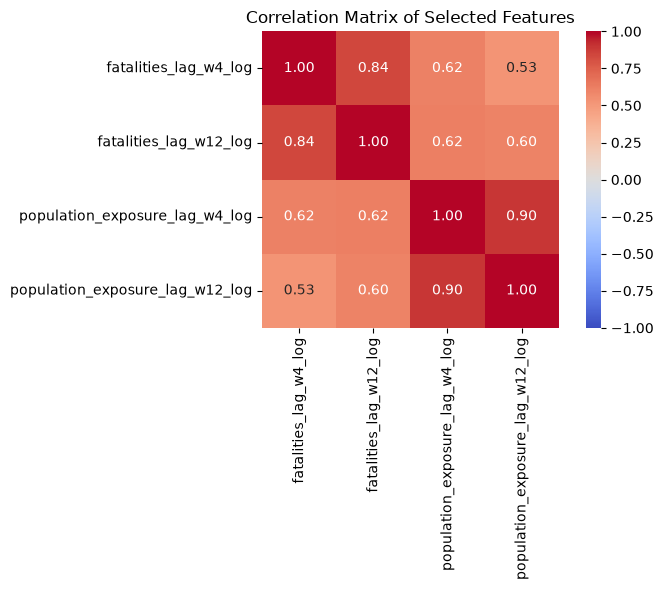

In [6]:
df = model_df

# Select features
features = [
    'fatalities_lag_w4_log',
    'fatalities_lag_w12_log',
    'population_exposure_lag_w4_log',
    'population_exposure_lag_w12_log'
]

# Calculate correlation matrix
corr_matrix = df[features].corr(method='pearson')

# Display correlation matrix
print(corr_matrix.round(2))

# Plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    fmt='.2f',
    square=True
)

plt.title('Correlation Matrix of Selected Features')
plt.tight_layout()
plt.show()

In [7]:
!pip install statsmodels

# 2. Logistic Regression for classification problem
- Interested in identifying and predicting conflict events associated with five or more fatalities (≥5).
- Use logistic regression as a binary classification model to estimate the probability of an observation meeting this threshold.
- The objective is to identify the factors associated with higher-intensity conflict events and assess the model's ability to distinguish between positive and negative cases.

### Binary dependent variable:

1 = Conflict event with ≥5 fatalities.

0 = Conflict event with fewer than 5 fatalities (or no qualifying event, depending on the unit of observation).

### Key considerations

- Class imbalance: Assess the proportion of positive and negative observations. A relatively small number of observations meeting the ≥5 fatalities threshold may affect model performance.

- Classification threshold: The default 0.5 probability threshold may not be optimal. Test alternative thresholds and assess the trade-off between precision and recall.

- Feature selection: Examine multicollinearity, particularly between the 4-week and 12-week lagged fatality variables (Pearson correlation = 0.91).

- Model evaluation: Prioritise precision, recall, F1-score, PR-AUC and balanced accuracy rather than relying on overall accuracy alone.

- Temporal validation: Use time-based training and test splits to assess how well the model generalises to future observations.

- For evaluation: for this use case we dont mind false flags as much as missing out weeks of conflict increase. Therefore recall is prioritised because missing fatal violence is costlier than false flags.


- **Role:** interpretable baseline.
- **Setup:** standardised features, L2 regularisation, `class_weight='balanced'`.
- **Notes:** the lagged features are highly collinear (up to 0.91), so regularisation is needed. Tune the regularisation strength `C`.
- **Output:** coefficients (as odds ratios) showing direction and size of each effect.

In [8]:
pct = df["dummy_conflict"].value_counts(normalize=True).mul(100).round(2)
print(pct)

dummy_conflict
0    91.91
1     8.09
Name: proportion, dtype: float64


### Data Preparation and Temporal Split

The dataset is structured at the state-week level, with `dummy_conflict` as the binary target variable. The training period was revised from 1997 to 2010 because earlier observations contain a greater proportion of low-intensity conflict weeks, making them less representative of the conflict patterns in the more recent modelling period as shown in the EDA, I ran the models before with 1997-2010 coverage and it showed this too as well as changes to ACLED's methodological changes.

The data is divided chronologically into training (2010–2021), validation (2022–2023) and test (2024–August 2026) sets. Three-month gaps are applied between periods to reduce potential temporal overlap arising from features constructed using historical lags of up to 12 weeks.

In [86]:
import numpy as np, pandas as pd

from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             roc_auc_score, average_precision_score)

# =====================================================================
# 1. CONFIG
# =====================================================================
date_col = "week"
target   = "dummy_conflict"

# Time windows (train starts in 2010 because of the change in methodology and
# conflict patterns; earlier years are sparse and not comparable)
train_start = pd.Timestamp("2010-01-01")
val_start   = pd.Timestamp("2022-01-01")
test_start  = pd.Timestamp("2024-01-01")
test_end    = pd.Timestamp("2026-08-31")

# Gap between sets: lags reach back 12 weeks, so features near the end of one set
# would otherwise be built from weeks inside the next. 3 months covers that.
gap = pd.DateOffset(months=3)

# Resulting split:
#   train      2010-01-01 to 2021-09-30   (ends one gap before validation)
#   validation 2022-01-01 to 2023-09-30   (ends one gap before test)
#   test       2024-01-01 to 2026-08-31

categorical = ["admin1"]

lag_feat = [
    "fatalities_lag_w4_log",
    "fatalities_lag_w12_log",
    "population_exposure_lag_w4_log",
    "population_exposure_lag_w12_log",
]

# Other features were tried: is_election_year added no predictive power, so it is left out.
# numeric_feat = ["is_election_year"]
feats = lag_feat + categorical

# =====================================================================
# 2. CLEAN
# =====================================================================
df[date_col] = pd.to_datetime(df[date_col], errors="coerce")

df = (
    df.dropna(subset=[date_col, target] + feats)
      .sort_values([date_col, "admin1"])
      .reset_index(drop=True)
)

df[target] = df[target].astype(int)

# =====================================================================
# 3. TEMPORAL TRAIN / VALIDATION / TEST SPLIT
# =====================================================================

d = df[date_col]

# FIX: train now has a lower bound (train_start). Before, it was only
# d < (val_start - gap), which pulled in every week back to 1997.
m_train = (d >= train_start) & (d < (val_start - gap))

m_val = (
    (d >= val_start) &
    (d < (test_start - gap))
)

m_test = (
    (d >= test_start) &
    (d <= test_end)
)

df_train = df.loc[m_train].copy()
df_val   = df.loc[m_val].copy()
df_test  = df.loc[m_test].copy()

# =====================================================================
# 4. DEFINE FEATURES AND TARGET
# =====================================================================

X_train_raw = df_train[feats]
X_val_raw   = df_val[feats]
X_test_raw  = df_test[feats]

y_train = df_train[target].to_numpy()
y_val   = df_val[target].to_numpy()
y_test  = df_test[target].to_numpy()



In [87]:
X_train_raw

,fatalities_lag_w4_log,fatalities_lag_w12_log,population_exposure_lag_w4_log,population_exposure_lag_w12_log,admin1
25086,0.693147,0.693147,0.000000,0.000000,Abia
25087,0.000000,0.000000,0.000000,0.000000,Adamawa
25088,0.000000,0.000000,0.000000,0.000000,Akwa Ibom
25089,0.693147,0.693147,0.000000,0.000000,Anambra
25090,2.197225,2.197225,0.000000,0.000000,Bauchi
...,...,...,...,...,...
47762,2.484907,3.367296,13.190631,14.563540,Rivers
47763,3.663562,4.430817,12.157229,13.135767,Sokoto
47764,1.098612,3.044522,11.159132,13.056476,Taraba
47765,2.772589,3.044522,12.812850,13.040218,Yobe


### Logistic Regression

Logistic Regression is used as a baseline classification model to estimate the probability of conflict occurring in a given state-week. The model uses four lagged predictors capturing previous fatalities and population exposure over 4- and 12-week periods, alongside state-level categorical indicators.

The categorical state variable is one-hot encoded using `DictVectorizer`. The model is fitted on the training set, with performance assessed on the validation and test sets.

In [88]:
# =====================================================================
# 5. DICTVECTORIZER
# =====================================================================

dv = DictVectorizer(sparse=False)


X_train = dv.fit_transform(
    X_train_raw.to_dict(orient="records")
)

X_val = dv.transform(
    X_val_raw.to_dict(orient="records")
)

X_test = dv.transform(
    X_test_raw.to_dict(orient="records")
)

feature_names = dv.get_feature_names_out()

print("\nFeature matrix shapes:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nFeatures:")
print(feature_names)


Feature matrix shapes:
X_train: (22681, 41)
X_val: (3404, 41)
X_test: (5143, 41)

Features:
['admin1=Abia' 'admin1=Adamawa' 'admin1=Akwa Ibom' 'admin1=Anambra'
 'admin1=Bauchi' 'admin1=Bayelsa' 'admin1=Benue' 'admin1=Borno'
 'admin1=Cross River' 'admin1=Delta' 'admin1=Ebonyi' 'admin1=Edo'
 'admin1=Ekiti' 'admin1=Enugu' 'admin1=Federal Capital Territory'
 'admin1=Gombe' 'admin1=Imo' 'admin1=Jigawa' 'admin1=Kaduna' 'admin1=Kano'
 'admin1=Katsina' 'admin1=Kebbi' 'admin1=Kogi' 'admin1=Kwara'
 'admin1=Lagos' 'admin1=Nassarawa' 'admin1=Niger' 'admin1=Ogun'
 'admin1=Ondo' 'admin1=Osun' 'admin1=Oyo' 'admin1=Plateau' 'admin1=Rivers'
 'admin1=Sokoto' 'admin1=Taraba' 'admin1=Yobe' 'admin1=Zamfara'
 'fatalities_lag_w12_log' 'fatalities_lag_w4_log'
 'population_exposure_lag_w12_log' 'population_exposure_lag_w4_log']


In [89]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [126]:
# =====================================================================
# 6. FIT LOGISTIC REGRESSION
# =====================================================================

model_log = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_log.fit(X_train, y_train)


# =====================================================================
# 7. PREDICT PROBABILITIES
# =====================================================================

val_probs = model_log.predict_proba(X_val)[:, 1]
test_probs = model_log.predict_proba(X_test)[:, 1]



# =====================================================================
# 8. EVALUATION
# =====================================================================

def evaluate_model(y_true, probs, threshold=0.25):

    preds = (probs >= threshold).astype(int)

    print("ROC-AUC:", roc_auc_score(y_true, probs))
    print("Average Precision:", average_precision_score(y_true, probs))
    print("Accuracy:", accuracy_score(y_true, preds))
    print("Precision:", precision_score(y_true, preds, zero_division=0))
    print("Recall:", recall_score(y_true, preds, zero_division=0))
    print("F1:", f1_score(y_true, preds, zero_division=0))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, preds))

    print("\nClassification Report:")
    print(classification_report(y_true, preds, zero_division=0))


print("\n================ VALIDATION RESULTS ================")
evaluate_model(y_val, val_probs)

print("\n================ TEST RESULTS ================")
evaluate_model(y_test, test_probs)


================ VALIDATION RESULTS ================
ROC-AUC: 0.8337450865530737
Average Precision: 0.6385106588589634
Accuracy: 0.8419506462984724
Precision: 0.5732946298984035
Recall: 0.6181533646322379
F1: 0.5948795180722891

Confusion Matrix:
[[2471  294]
 [ 244  395]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.89      0.90      2765
           1       0.57      0.62      0.59       639

    accuracy                           0.84      3404
   macro avg       0.74      0.76      0.75      3404
weighted avg       0.85      0.84      0.84      3404


================ TEST RESULTS ================
ROC-AUC: 0.8824905811815301
Average Precision: 0.7792347495944891
Accuracy: 0.8533929613066303
Precision: 0.7267489711934156
Recall: 0.6766283524904214
F1: 0.7007936507936507

Confusion Matrix:
[[3506  332]
 [ 422  883]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89   

In [85]:
print(len(y_tr), df_train[date_col].min().date(), df_train[date_col].max().date())
print("train positive rate:", y_tr.mean().round(3))

47767 1997-01-04 2021-09-25
train positive rate: 0.052


## 2.1 Interpretation
- Distinguish between conflict and non conflict weeks on the test set with 0.883 as ROC-AUC score.
- Precision: 75% of predicted conflict weeks in the test set were actual conflict weeks.
- Recall: The model identifies approximately 67% of actual conflict weeks, meaning some conflict occurrences remain undetected.
- Generalisation: Test performance is stronger than validation performance. This is encouraging, although the difference warrants attention when comparing models.
- Threshold: 0.25 is hte highest F1 and balanced accuracy. 

### limitations:
Missed weeks: about a third of high-intensity weeks go undetected, likely sudden escalations in states with little recent violence, which lag-based features cannot anticipate. Review which states and periods account for the misses.
Decision threshold: results seem to use a default cut-off. If early warning matters more than avoiding false alarms, lowering the threshold would raise recall at the cost of precision. Choose it on the validation set and apply it unchanged to the test set.
Baselines needed: compare against a persistence baseline (“high-intensity last week”) and a state-average baseline to show how much the model adds beyond simple rules.
Calibration: check calibration curves if predicted probabilities are to be read as risk levels.

In [91]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    accuracy_score, confusion_matrix,
    balanced_accuracy_score
)
import numpy as np
import pandas as pd

thresholds = np.arange(0.05, 0.51, 0.025)

results = []

for threshold in thresholds:

    predictions = (val_probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "threshold": round(threshold, 3),
        "precision": precision_score(y_val, predictions, zero_division=0),
        "recall": recall_score(y_val, predictions, zero_division=0),
        "f1": f1_score(y_val, predictions, zero_division=0),
        "specificity": tn / (tn + fp),
        "balanced_accuracy": balanced_accuracy_score(y_val, predictions),
        "predicted_positive_rate": predictions.mean(),
        "false_negatives": fn,
        "false_positives": fp
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(3).to_string(index=False))

 threshold  precision  recall    f1  specificity  balanced_accuracy  predicted_positive_rate  false_negatives  false_positives
     0.050      0.256   0.931 0.402        0.375              0.653                    0.683               44             1729
     0.075      0.302   0.883 0.450        0.529              0.706                    0.548               75             1303
     0.100      0.352   0.828 0.494        0.648              0.738                    0.441              110              972
     0.125      0.404   0.768 0.530        0.739              0.753                    0.357              148              723
     0.150      0.443   0.715 0.547        0.792              0.754                    0.303              182              574
     0.175      0.479   0.671 0.559        0.831              0.751                    0.263              210              467
     0.200      0.524   0.646 0.579        0.864              0.755                    0.231              226  

In [92]:
# =====================================================================
# 9. FEATURE IMPORTANCE (COEFFICIENTS)
# =====================================================================

coef_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": model.coef_[0],
    "Odds_Ratio": np.exp(model.coef_[0])
})

coef_table = coef_table.sort_values(
    "Coefficient",
    ascending=False
)

print("\nLogistic Regression Coefficients:")
print(coef_table.to_string(index=False))


Logistic Regression Coefficients:
                         Feature  Coefficient  Odds_Ratio
                    admin1=Borno     2.247219    9.461392
                    admin1=Benue     0.843439    2.324347
                  admin1=Zamfara     0.738841    2.093509
                   admin1=Kaduna     0.705448    2.024754
                  admin1=Plateau     0.647816    1.911362
                  admin1=Katsina     0.614392    1.848532
                   admin1=Taraba     0.612037    1.844185
                     admin1=Yobe     0.599489    1.821188
                  admin1=Adamawa     0.557712    1.746672
                    admin1=Niger     0.547476    1.728883
          fatalities_lag_w12_log     0.377487    1.458614
                admin1=Nassarawa     0.302135    1.352744
              admin1=Cross River     0.280435    1.323705
           fatalities_lag_w4_log     0.238967    1.269936
                     admin1=Kano     0.214221    1.238896
                   admin1=Rivers     

In [15]:
## what does this show?

In [16]:
#for different thresholds for conflict 

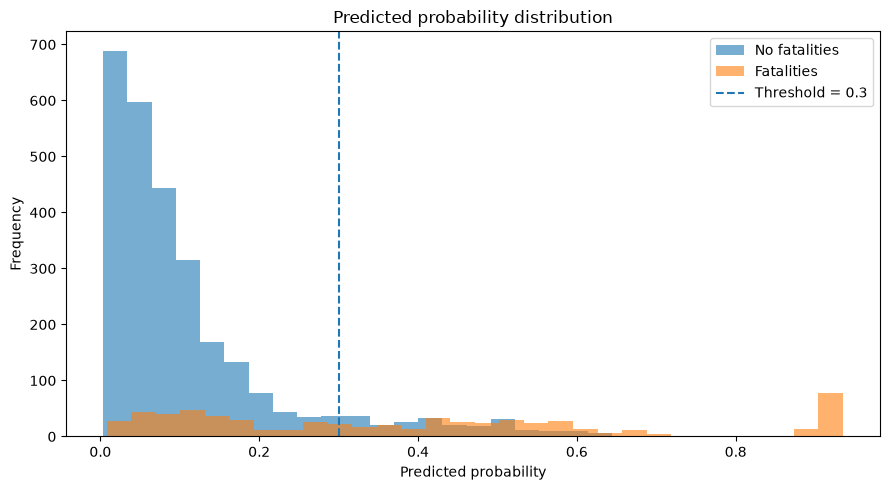

In [94]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    val_probs[y_val == 0],
    bins=30,
    alpha=0.6,
    label="No fatalities"
)

plt.hist(
    val_probs[y_val == 1],
    bins=30,
    alpha=0.6,
    label="Fatalities"
)

plt.axvline(0.3, linestyle="--", label="Threshold = 0.3")

plt.xlabel("Predicted probability")
plt.ylabel("Frequency")
plt.title("Predicted probability distribution")
plt.legend()
plt.tight_layout()
plt.show()

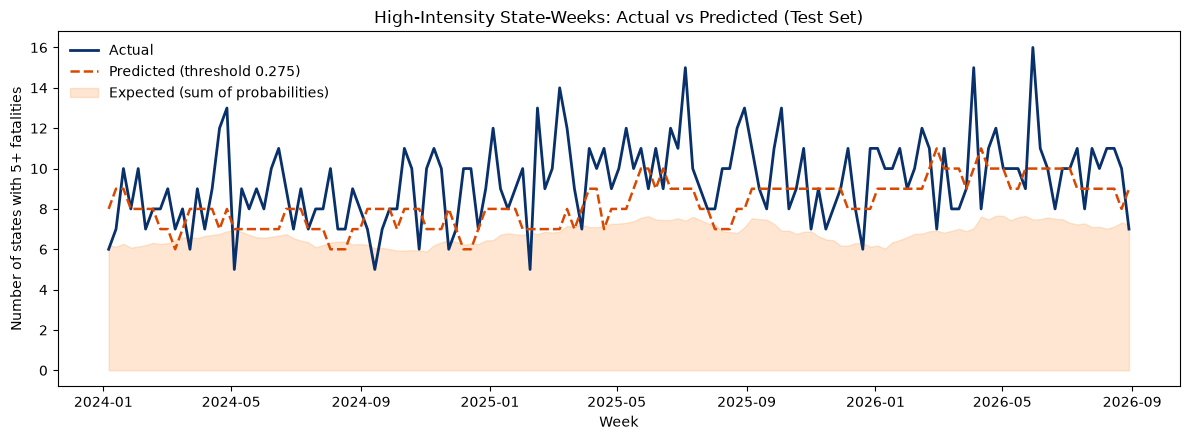

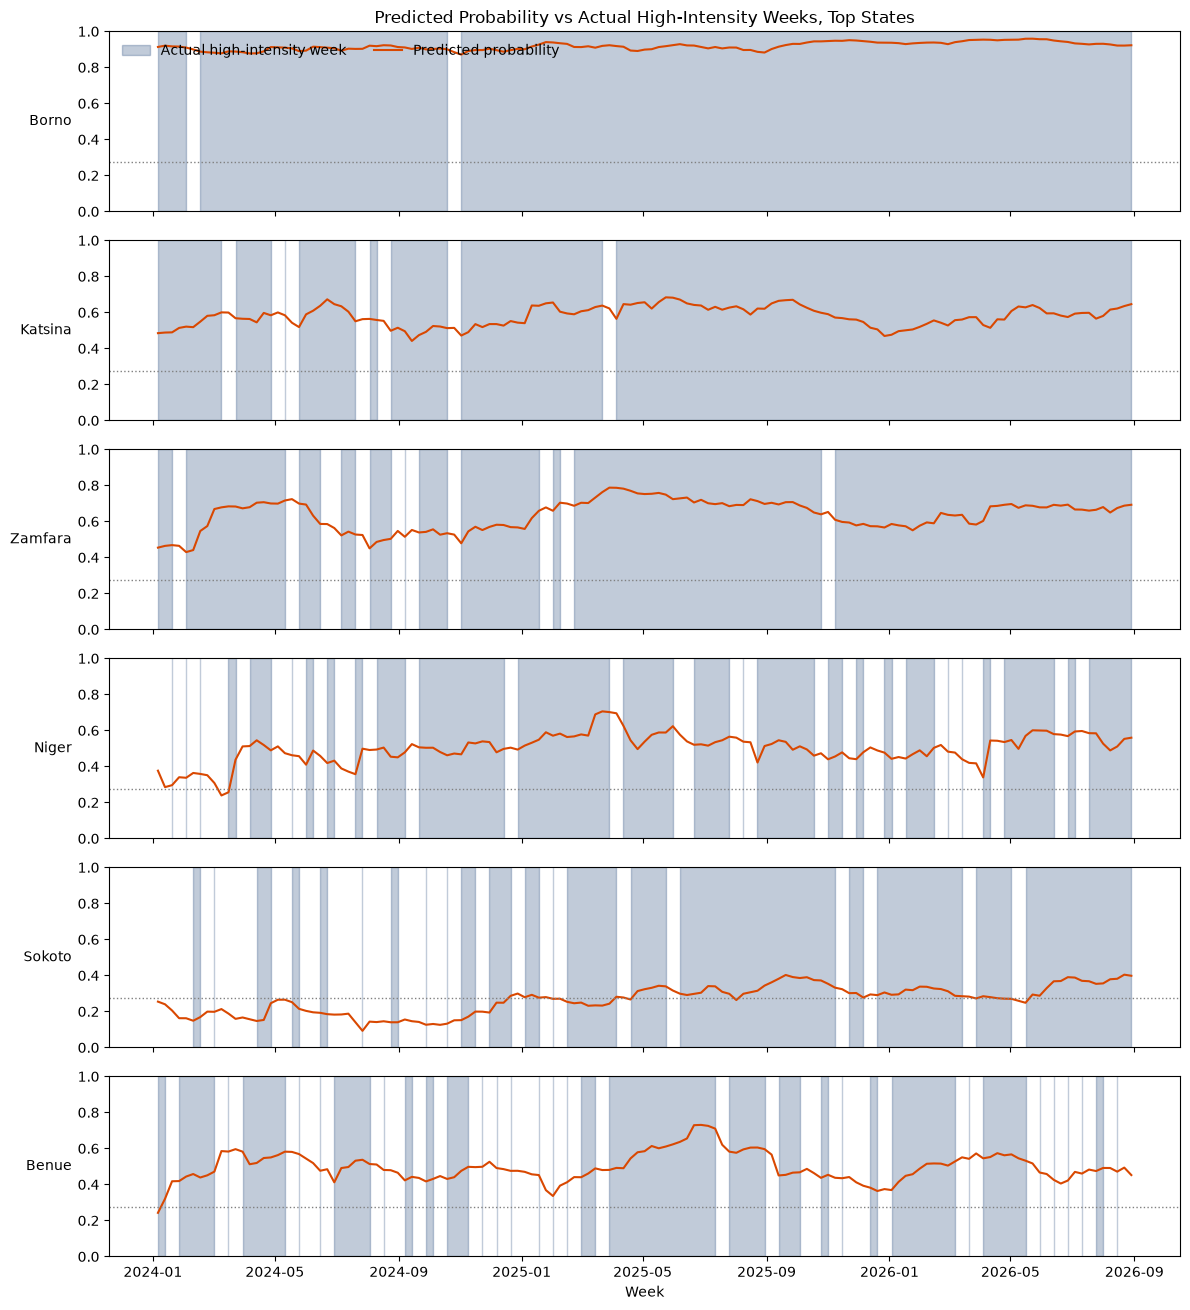

In [95]:
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# 0. Build a results table (test_df = test rows of model_df, same order as y_test)
# ------------------------------------------------------------
threshold = 0.275   # the cut-off you chose on the validation set

results = df_test[['admin1', 'week']].copy().reset_index(drop=True)
results['actual'] = np.asarray(y_test).ravel()
results['prob'] = np.asarray(test_probs).ravel()
results['pred'] = (results['prob'] >= threshold).astype(int)
# ------------------------------------------------------------
# 1. National view: high-intensity states per week, actual vs predicted
# ------------------------------------------------------------
weekly = (results.groupby('week')
                 .agg(actual=('actual', 'sum'),
                      predicted=('pred', 'sum'),
                      expected=('prob', 'sum')))

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(weekly.index, weekly['actual'], color='#08306b', linewidth=2,
        label='Actual')
ax.plot(weekly.index, weekly['predicted'], color='#d94801', linewidth=1.8,
        linestyle='--', label=f'Predicted (threshold {threshold})')
ax.fill_between(weekly.index, weekly['expected'], color='#fdae6b', alpha=0.3,
                label='Expected (sum of probabilities)')

ax.set_title('High-Intensity State-Weeks: Actual vs Predicted (Test Set)')
ax.set_ylabel('Number of states with 5+ fatalities')
ax.set_xlabel('Week')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2. State view: predicted probability vs actual high-intensity weeks
# ------------------------------------------------------------
top_states = (results.groupby('admin1')['actual'].sum()
                     .sort_values(ascending=False).head(6).index)

fig, axes = plt.subplots(len(top_states), 1, figsize=(12, 2.2 * len(top_states)),
                         sharex=True)

for ax, state in zip(axes, top_states):
    s = results[results['admin1'] == state].sort_values('week')
    ax.fill_between(s['week'], 0, 1, where=s['actual'] == 1,
                    color='#08306b', alpha=0.25, step='mid',
                    label='Actual high-intensity week')
    ax.plot(s['week'], s['prob'], color='#d94801', linewidth=1.5,
            label='Predicted probability')
    ax.axhline(threshold, color='grey', linestyle=':', linewidth=1)
    ax.set_ylim(0, 1)
    ax.set_ylabel(state, rotation=0, ha='right', va='center')

axes[0].legend(frameon=False, loc='upper left', ncol=2)
axes[0].set_title('Predicted Probability vs Actual High-Intensity Weeks, Top States')
axes[-1].set_xlabel('Week')
plt.tight_layout()
plt.show()

In [20]:
y_test

array([0, 0, 0, ..., 0, 0, 1], shape=(5143,))

# 2. Random forest model

- **Role:** non-linear model that handles interactions and collinearity without scaling.
- **Setup:** `class_weight='balanced_subsample'`, tune `n_estimators`, `max_depth`, `min_samples_leaf`, and `max_features`.
- **Output:** feature importance (permutation importance preferred over impurity-based).

Random Forest is used as a non-linear classification model to capture potential relationships and interactions between predictors. It combines multiple decision trees, with predictions aggregated across the forest.

The model uses 500 trees, a maximum depth of None, a minimum leaf size of 10 and square-root feature sampling. Class weights are not applied. State-level categorical variables are one-hot encoded using DictVectorizer.

In [111]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             balanced_accuracy_score, f1_score, confusion_matrix, roc_curve)

In [112]:
X_train_raw = df_train[feats].copy()
X_val_raw = df_val[feats].copy()
X_test_raw = df_test[feats].copy()

# Impute numeric missing values using training data only
#medians = X_train_raw[numeric_feat].median()

#for X in [X_train_raw, X_val_raw, X_test_raw]:
   # X[numeric_feat] = X[numeric_feat].fillna(medians)
  #  X[categorical] = X[categorical].fillna("Unknown").astype(str)


In [113]:
# -----------------------------
# 3. Encode categorical variables
# -----------------------------

dv = DictVectorizer(sparse=True)

X_train = dv.fit_transform(
    X_train_raw.to_dict(orient="records")
)

X_val = dv.transform(
    X_val_raw.to_dict(orient="records")
)

X_test = dv.transform(
    X_test_raw.to_dict(orient="records")
)

# -----------------------------
# 4. Train Random Forest
# -----------------------------

rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=20,
    min_samples_leaf=10,
    max_features="sqrt",
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predicted probabilities
val_probs_rf = rf_model.predict_proba(X_val)[:, 1]
test_probs_rf = rf_model.predict_proba(X_test)[:, 1]


In [24]:
val_probs_rf

array([0.0890125 , 0.0041031 , 0.09630737, ..., 0.36617387, 0.06530775,
       0.17514121], shape=(3404,))

## 2.2  Model Evaluation and Threshold Selection

Performance is evaluated using ROC-AUC, Average Precision and threshold-dependent classification metrics. The classification threshold is varied using validation predictions to examine the trade-off between precision and recall.

A threshold of 0.28 is used for the initial model evaluation.

In [ ]:
# -----------------------------
# 5. Evaluate model
# -----------------------------

def evaluate_model(y_true, probs, threshold=0.20): #from the threshold output as the higher F1 0.58

    predictions = (probs >= threshold).astype(int)

    print("ROC-AUC:", round(roc_auc_score(y_true, probs), 3))
    print("Average Precision:", round(average_precision_score(y_true, probs), 3))
    print("Accuracy:", round(accuracy_score(y_true, predictions), 3))
    print("Precision:", round(precision_score(y_true, predictions, zero_division=0), 3))
    print("Recall:", round(recall_score(y_true, predictions, zero_division=0), 3))
    print("F1:", round(f1_score(y_true, predictions, zero_division=0), 3))
    print("Predicted positive rate:", round(predictions.mean(), 3))

    print("\nConfusion matrix:")
    print(confusion_matrix(y_true, predictions))


print("VALIDATION RESULTS")
evaluate_model(y_val, val_probs_rf)

print("\nTEST RESULTS")
evaluate_model(y_test, test_probs_rf)

VALIDATION RESULTS
ROC-AUC: 0.836
Average Precision: 0.637
Accuracy: 0.839
Precision: 0.567
Recall: 0.599
F1: 0.583
Predicted positive rate: 0.198

Confusion matrix:
[[2473  292]
 [ 256  383]]

TEST RESULTS
ROC-AUC: 0.891
Average Precision: 0.795
Accuracy: 0.854
Precision: 0.712
Recall: 0.712
F1: 0.712
Predicted positive rate: 0.254

Confusion matrix:
[[3462  376]
 [ 376  929]]


## 2.2 Interpretation 

- Ability to distinguish from 0.89 form high intensity from non intensity weeks
- Test performance: 71% high intensity weeks with approx. 71% of positive predictions being correct.
- Validation: Revall is lower in val, suggesting missing substanial positive week, test having higher recall.
- feature importance: previous fatalities strongest predictors, 12 week lag followed by the 4 week lag. 


In [115]:
importance = pd.DataFrame({
    "feature": dv.get_feature_names_out(),
    "importance": rf_model.feature_importances_
}).sort_values("importance", ascending=False)

print(importance.head(20))

                            feature  importance
37           fatalities_lag_w12_log    0.300032
38            fatalities_lag_w4_log    0.270459
39  population_exposure_lag_w12_log    0.133544
40   population_exposure_lag_w4_log    0.106670
7                      admin1=Borno    0.106668
18                    admin1=Kaduna    0.011064
31                   admin1=Plateau    0.010359
6                      admin1=Benue    0.010105
36                   admin1=Zamfara    0.006476
1                    admin1=Adamawa    0.005661
35                      admin1=Yobe    0.004975
34                    admin1=Taraba    0.004206
20                   admin1=Katsina    0.003571
26                     admin1=Niger    0.002666
24                     admin1=Lagos    0.001706
32                    admin1=Rivers    0.001638
25                 admin1=Nassarawa    0.001576
19                      admin1=Kano    0.001562
8                admin1=Cross River    0.001497
9                      admin1=Delta    0

In [116]:
thresholds = np.arange(0.05, 0.51, 0.025)

results = []

for threshold in thresholds:

    predictions = (val_probs_rf >= threshold).astype(int)

    results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(y_val, predictions, zero_division=0),
        "recall": recall_score(y_val, predictions, zero_division=0),
        "f1": f1_score(y_val, predictions, zero_division=0),
        "accuracy": accuracy_score(y_val, predictions),
        "predicted_positive_rate": predictions.mean()
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(3).to_string(index=False))

 threshold  precision  recall    f1  accuracy  predicted_positive_rate
      0.05      0.237   0.958 0.380     0.413                    0.759
      0.08      0.267   0.920 0.414     0.511                    0.647
      0.10      0.317   0.867 0.464     0.624                    0.514
      0.13      0.369   0.831 0.511     0.702                    0.422
      0.15      0.405   0.770 0.531     0.745                    0.357
      0.18      0.464   0.726 0.566     0.791                    0.294
      0.20      0.496   0.698 0.580     0.810                    0.264
      0.23      0.509   0.667 0.577     0.817                    0.246
      0.25      0.537   0.642 0.584     0.829                    0.224
      0.28      0.558   0.604 0.580     0.836                    0.203
      0.30      0.581   0.570 0.575     0.842                    0.184
      0.33      0.607   0.538 0.570     0.848                    0.167
      0.35      0.623   0.501 0.555     0.849                    0.151
      

In [119]:
from sklearn.metrics import confusion_matrix, classification_report

# Generate predictions directly from the fitted RF
rf_val_probs = rf_model.predict_proba(X_val)[:, 1]
rf_val_preds = (rf_val_probs >= 0.5).astype(int)

print("Observations:", len(y_val))
print("Actual positives:", y_val.sum())
print("Predicted positives:", rf_val_preds.sum())

print("\nConfusion matrix:")
print(confusion_matrix(y_val, rf_val_preds))

print("\nClassification report:")
print(classification_report(y_val, rf_val_preds))

Observations: 3404
Actual positives: 639
Predicted positives: 290

Confusion matrix:
[[2696   69]
 [ 418  221]]

Classification report:
              precision    recall  f1-score   support

           0       0.87      0.98      0.92      2765
           1       0.76      0.35      0.48       639

    accuracy                           0.86      3404
   macro avg       0.81      0.66      0.70      3404
weighted avg       0.85      0.86      0.83      3404



In [120]:
from sklearn.metrics import roc_auc_score, average_precision_score

rng = np.random.default_rng(42)

features_to_test = feats

importance_results = []

baseline_auc = roc_auc_score(y_val, val_probs_rf)
baseline_ap = average_precision_score(y_val, val_probs_rf)

for feature in features_to_test:

    auc_drops = []
    ap_drops = []

    for _ in range(20):

        shuffled = X_val_raw.copy()
        shuffled[feature] = rng.permutation(shuffled[feature].values)

        X_shuffled = dv.transform(
            shuffled.to_dict(orient="records")
        )

        shuffled_probs = rf_model.predict_proba(X_shuffled)[:, 1]

        auc_drops.append(
            baseline_auc - roc_auc_score(y_val, shuffled_probs)
        )

        ap_drops.append(
            baseline_ap - average_precision_score(y_val, shuffled_probs)
        )

    importance_results.append({
        "feature": feature,
        "ROC_AUC_drop": np.mean(auc_drops),
        "AP_drop": np.mean(ap_drops)
    })

permutation_importance = pd.DataFrame(
    importance_results
).sort_values("AP_drop", ascending=False)

print(permutation_importance.round(4))

                           feature  ROC_AUC_drop  AP_drop
1           fatalities_lag_w12_log        0.0528   0.0887
0            fatalities_lag_w4_log        0.0308   0.0531
4                           admin1        0.0183   0.0230
2  population_exposure_lag_w12_log        0.0043   0.0102
3   population_exposure_lag_w4_log        0.0028   0.0040


Permutation importance indicates that lagged fatalities contribute most to the Random Forest's predictive performance. The 12-week fatality lag has the largest impact on both ROC-AUC and Average Precision, followed by the 4-week lag. State (`admin1`) also contributes to model performance, while population exposure variables have comparatively small effects. Overall, the model relies more heavily on recent conflict history than on population exposure.

- **Fatality history is confirmed as the main driver.** Shuffling the 12-week fatality lag costs 0.05 ROC-AUC and 0.08 AP, the largest drop by far, and the 4-week lag is second.
- **State identity matters more than the built-in importance suggested.** Taken as one feature, `admin1` ranks third, ahead of both exposure lags, so the state baselines carry real information.
- **Exposure matters much less here than in the built-in importance.** It ranked at about 29% there, but shuffling it costs under 0.006 ROC-AUC. Exposure is correlated with the fatality lags (0.44 to 0.53), so when it is shuffled the model recovers most of its signal from them. Treat it as largely redundant.
- **Same ordering on both metrics**, which makes the ranking more reliable. The drops are larger for AP, the metric most sensitive to the rare high-intensity class.

## 4. Caveats and next steps
 
- **Importance is not direction.** It shows which features the model uses, not whether more of them raises or lowers risk. Use partial dependence or SHAP for direction.
- **Correlated features share importance.** The 4- and 12-week lags are correlated (0.84 for fatalities), so how importance splits between them is somewhat arbitrary. Read each pair as a group, not as a ranking of individual features.
- **Importance method:** if this is the forest's built-in (impurity-based) importance, it tends to favour continuous features over binary dummies. Confirm with permutation importance on the validation or test set before drawing strong conclusions.
- **Features not shown:** the top 20 contain no event-count lags, 1-week lags, `is_election_year`, or `month`, so their importance is below 0.0015 or they weren't in the model. If they were, the election flag adds essentially nothing, consistent with the near-zero correlation seen earlier. Confirm which features went into the model.
- **State dummies:** including admin1 lets the model learn state baselines, which can help forecasts but may reduce generalisation to states with few high-intensity weeks. Worth testing a version without them.
- **Missed weeks:** 29% (test) to 40% (validation) of high-intensity weeks go undetected, likely sudden escalations in states with little recent violence, which lag-based features cannot anticipate. Review which states and periods account for them.
- **Baselines:** compare against a persistence rule ("high-intensity last week") and a state-average rule, to show what the forest adds beyond simple history.
- **Threshold:** results depend on the cut-off, which should be chosen on validation data and applied unchanged to test. A lower threshold would raise recall at the cost of precision if missed escalations are costlier than false alarms.
- **Calibration:** forest probabilities are often poorly calibrated, so check calibration curves before reading them as risk levels.
- **Drift:** more high-intensity weeks in the test period suggests conflict intensifying over time. The model generalised here, but monitor it on future data.

# 3.  XGBOOST Model

- Tree - based ML method, builds prediction by adding up many small trees one after another.
- Repeats for many rounds, each new tree focuses on previous trees got wrong, stops when additional trees do not improve performance
- Probability state-week has a high intensity conflict--> YES/NO warning.
- Also looks at non-linear patterns and interactions: conflict risk may depend on combination of features e.g. high conflict in Borneo that linear model cannot account for
- Handles correlated features such as lags features 
- Built for imbalanced data- e.g. using the `scale_pos_weight` to give minority class more weight.
- Regularisation: learning rate, tree depth, minimum leaf weight and subsampling all limit overfitting.
- Understanding the drivers: feature importance, permutation importance, SHAP values show which features drive predictions and direction.
- Benchmark against other models.

In [48]:
# =============================================================
# XGBoost hyperparameter tuning and model selection
# -------------------------------------------------------------
# Purpose : fit XGBoost over a small grid and keep the configuration
#           with the best validation ROC-AUC.
# Target  : dummy_conflict (1 if a state-week has 5+ fatalities).
# Inputs  : X_tr, y_tr = training set (earlier weeks)
#           X_va, y_va = validation set (later weeks, time-ordered)
# Output  : `grid` = table of all 12 configurations, ranked
#           `xgb`  = fitted model with the best validation ROC-AUC
# =============================================================

In [30]:
from xgboost import XGBClassifier

In [106]:
import numpy as np, pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             balanced_accuracy_score, confusion_matrix)
                                 # your 5+ fatalities flag
categorical = ["admin1"]

lag_feat = [
 "fatalities_lag_w4_log",
    "fatalities_lag_w12_log",
    "population_exposure_lag_w12_log",
    "population_exposure_lag_w4_log"

]

# --- design matrix: dummies learned on TRAIN, same columns for val/test ---
cols = pd.get_dummies(df.loc[m_train, categorical + lag_feat], columns=categorical, dtype=float).columns
def build(m):
    return pd.get_dummies(df.loc[m, categorical + lag_feat], columns=categorical,
                          dtype=float).reindex(columns=cols, fill_value=0.0)

X_tr, X_va, X_te = build(m_train), build(m_val), build(m_test)
y_tr, y_va, y_te = (df.loc[m, target].to_numpy() for m in (m_train, m_val, m_test))

In [41]:
X_tr

,fatalities_lag_w4_log,fatalities_lag_w12_log,population_exposure_lag_w12_log,population_exposure_lag_w4_log,admin1_Abia,admin1_Adamawa,admin1_Akwa Ibom,admin1_Anambra,admin1_Bauchi,admin1_Bayelsa,...,admin1_Ogun,admin1_Ondo,admin1_Osun,admin1_Oyo,admin1_Plateau,admin1_Rivers,admin1_Sokoto,admin1_Taraba,admin1_Yobe,admin1_Zamfara
0,0.000000,0.000000,0.000000,0.000000,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47762,3.332205,3.526361,13.989163,13.202180,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
47763,2.772589,3.555348,14.641712,13.292631,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
47764,4.043051,4.976734,14.635034,13.525837,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
47765,0.000000,2.397895,13.197105,11.081681,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [43]:
y_tr

array([0, 0, 0, ..., 0, 0, 0], shape=(47767,))

In [107]:


# --- small grid, chosen on validation AUC (kept small: validation is only ~700 positives) ---
rows, models = [], {}
for depth in [2, 3, 4]: #tree depth: deeper more interactions/more overfitting
    for lr in [0.03, 0.1]: # learning rate: lower = slower learning, needs more trees 
        for mcw in [10, 50]: # min_child_weight
            xgb = XGBClassifier(
                n_estimators=1000, learning_rate=lr, max_depth=depth,
                min_child_weight=mcw, subsample=0.8, colsample_bytree=0.8,
                reg_lambda=5.0, eval_metric="auc",
                early_stopping_rounds=50,           # stops on validation AUC
                n_jobs=-1, random_state=0)
            xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
            p = xgb.predict_proba(X_va)[:, 1]
            key = (depth, lr, mcw)
            models[key] = xgb
            rows.append({"depth": depth, "lr": lr, "min_child_w": mcw,
                         "trees": xgb.best_iteration + 1,
                         "val_AUC": roc_auc_score(y_va, p),
                         "val_AP": average_precision_score(y_va, p)})

grid = pd.DataFrame(rows).sort_values("val_AUC", ascending=False)
print(grid.round(4).to_string(index=False))
best = grid.iloc[0]
xgb = models[(int(best.depth), best.lr, int(best.min_child_w))]



 depth   lr  min_child_w  trees  val_AUC  val_AP
     2 0.03           10    280   0.8393  0.6347
     2 0.10           10     84   0.8391  0.6334
     3 0.03           10    254   0.8390  0.6375
     3 0.10           10     83   0.8382  0.6340
     2 0.10           50     88   0.8379  0.6361
     4 0.03           10    174   0.8378  0.6348
     4 0.10           10     62   0.8374  0.6313
     2 0.03           50    170   0.8374  0.6340
     3 0.03           50    130   0.8368  0.6342
     3 0.10           50     67   0.8368  0.6350
     4 0.03           50    130   0.8366  0.6352
     4 0.10           50     33   0.8363  0.6331


In [ ]:
# best one is 3 depth, 0.1 lr, min_child_w, 10, trees is 61, val AUC is 0.831, val_AP 0.631

#shallow trees, few rees, 
#possible drift- conflict intensity increases over time as shown in the EDA- test look better than validation.


In [45]:
xgb

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [108]:
# --- threshold sweep on VALIDATION (same format as your other models) ---
p_va = xgb.predict_proba(X_va)[:, 1]
sweep = []
for t in np.arange(0.05, 0.55, 0.025):
    pred = p_va >= t
    tn, fp, fn, tp = confusion_matrix(y_va, pred).ravel()
    sweep.append({"threshold": round(t, 3), "precision": tp / max(tp + fp, 1), "recall": tp / (tp + fn),
                  "specificity": tn / (tn + fp), "balanced_acc": balanced_accuracy_score(y_va, pred),
                  "predicted_pos_rate": pred.mean(), "FN": fn, "FP": fp})
print(pd.DataFrame(sweep).round(3).to_string(index=False))

# --- choose threshold from the sweep, then evaluate both sets ---
THRESH = 0.25                                        # replace after reading the sweep
for name, X, y in [("VALIDATION", X_va, y_va), ("TEST", X_te, y_te)]:
    p = xgb.predict_proba(X)[:, 1]
    pred = p >= THRESH
    print(f"\n{name}: ROC-AUC={roc_auc_score(y, p):.3f} | AP={average_precision_score(y, p):.3f} "
          f"(base rate {y.mean():.3f}) | flagged={pred.mean():.3f}")
    print(confusion_matrix(y, pred))

 threshold  precision  recall  specificity  balanced_acc  predicted_pos_rate  FN   FP
     0.050      0.239   0.956        0.296         0.626               0.751  28 1947
     0.075      0.288   0.909        0.480         0.695               0.593  58 1437
     0.100      0.329   0.867        0.592         0.730               0.494  85 1128
     0.125      0.386   0.804        0.704         0.754               0.391 125  818
     0.150      0.433   0.754        0.772         0.763               0.327 157  630
     0.175      0.478   0.715        0.820         0.767               0.281 182  499
     0.200      0.505   0.676        0.847         0.762               0.251 207  423
     0.225      0.527   0.651        0.865         0.758               0.232 223  373
     0.250      0.540   0.617        0.879         0.748               0.214 245  335
     0.275      0.560   0.577        0.895         0.736               0.194 270  290
     0.300      0.600   0.557        0.914         0.7

In [ ]:
sw = pd.DataFrame(sweep)
sw["f1"] = 2 * sw.precision * sw.recall / (sw.precision + sw.recall)

# Rule 1: F1 peak
print(sw.loc[sw.f1.idxmax(), ["threshold", "precision", "recall", "f1", "predicted_pos_rate"]])

# Rule 2: highest threshold with recall >= 0c.70
print(sw[sw.recall >= 0.70].iloc[-1][["threshold", "precision", "recall", "predicted_pos_rate"]])

threshold             0.225000
precision             0.527250
recall                0.651017
f1                    0.582633
predicted_pos_rate    0.231786
Name: 7, dtype: float64
threshold             0.175000
precision             0.478033
recall                0.715180
predicted_pos_rate    0.280846
Name: 5, dtype: float64


- Imbalance: no class weighting, handled through decision threshold, tried weighting and dropped a run with scale_pos_weight = 18.33 (training negatives/positives so only about 5% training weeks are high intensity, given the same ranking in performance.)

### Model Performance

- XGBoost achieves a validation ROC-AUC of 0.839 and Average Precision of 0.635, increasing to 0.893 and 0.797 respectively on the test set. At the selected threshold of 0.25, the model detects approximately 62% of positive validation observations and 72% of positive test observations.

- The stronger test performance should be interpreted alongside the higher prevalence of positive observations in the test period (25.4%, compared with 18.8% in validation).
- Imbalance: no class weighting, handled through decision threshold, tried weighting and dropped a run with scale_pos_weight = 18.33 (training negatives/positives so only about 5% training weeks are high intensity, given the same ranking in performance.)

XGBoost separates high-intensity state-weeks well and performs almost identically to the random forest. On the test set it reaches a ROC-AUC of 0.89 and an average precision of 0.79. At the chosen threshold, it catches 66% of high-intensity weeks with 76% precision.
- **Good ranking ability:** a ROC-AUC of 0.84 to 0.89 means the model usually gives higher risk to weeks that turn out high-intensity than to those that don't.
- **Beats the majority baseline:** always predicting "not high-intensity" scores 81% accuracy on validation and 75% on test. XGBoost scores 85% and 86%, and identifies the weeks that matter.
- **Well above chance:** average precision is about 3.4 times the validation base rate (0.188) and 3.1 times the test base rate (0.254).
- **Error trade-off on the test set:**
  - It catches 858 of 1,305 high-intensity weeks (66%) and misses 447 (34%).
  - It raises 278 false alarms, about 3.1 correct warnings per false alarm.
  - The false-alarm rate among non-conflict weeks is 7.2%.
  - On validation it is weaker: it catches 56% (358 of 639), misses 281, and raises 245 false alarms (1.5 correct warnings each).
- **Under-flagging:** it flags 22% of test weeks when 25% really were high-intensity. It is slightly conservative, which is why precision (0.76) exceeds recall (0.66).
- **Higher test scores partly reflect prevalence:** the test period has more high-intensity weeks (25% against 19%), which lifts precision and average precision. ROC-AUC is less sensitive to prevalence, and its rise from 0.84 to 0.89 shows the model held up on later data.

In [121]:
!pip install shap

In [35]:
print(X_val.shape, X_test.shape, len(feature_names))

(3404, 41) (5143, 41) 41


In [36]:
feature_names = list(df_train.columns)   # whatever DataFrame you fed in, before it became an array

In [37]:
feature_names

['admin1',
 'week',
 'year',
 'dummy_conflict',
 'dummy_fat',
 'events_lag_w1_log',
 'events_lag_w4_log',
 'events_lag_w12_log',
 'fatalities_lag_w1_log',
 'fatalities_lag_w4_log',
 'fatalities_lag_w12_log',
 'population_exposure_lag_w1_log',
 'population_exposure_lag_w4_log',
 'population_exposure_lag_w12_log',
 'month']

In [124]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

THRESH = 0.25

results = []

for name, X, y in [
    ("Validation", X_va, y_va),
    ("Test", X_te, y_te)
]:
    p = rf_model.predict_proba(X)[:, 1]
    pred = (p >= THRESH).astype(int)

    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()

    results.append({
        "Dataset": name,
        "Threshold": THRESH,
        "ROC-AUC": roc_auc_score(y, p),
        "AP": average_precision_score(y, p),
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y, pred),
        "Actual Positives": int(y.sum()),
        "Predicted Positives": int(pred.sum()),
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn
    })

rf_results = pd.DataFrame(results)

print(rf_results.round(3).to_string(index=False))

/opt/anaconda3/envs/my-py314-env/lib/python3.13/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/envs/my-py314-env/lib/python3.13/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


   Dataset  Threshold  ROC-AUC    AP  Accuracy  Precision  Recall  F1  Balanced Accuracy  Actual Positives  Predicted Positives  TP  FP   TN   FN
Validation       0.25    0.568 0.209     0.812        0.0     0.0 0.0                0.5               639                    0   0   0 2765  639
      Test       0.25    0.572 0.280     0.746        0.0     0.0 0.0                0.5              1305                    0   0   0 3838 1305


In [125]:
for name, X, y in [
    ("VALIDATION", X_va, y_va),
    ("TEST", X_te, y_te)
]:
    p = rf_model.predict_proba(X)[:, 1]
    pred = (p >= THRESH).astype(int)

    print(f"\n{name}")
    print("Observations:", len(y))
    print("Actual positives:", int(y.sum()))
    print("Predicted positives:", int(pred.sum()))
    print("Confusion matrix:")
    print(confusion_matrix(y, pred))

/opt/anaconda3/envs/my-py314-env/lib/python3.13/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/envs/my-py314-env/lib/python3.13/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(



VALIDATION
Observations: 3404
Actual positives: 639
Predicted positives: 0
Confusion matrix:
[[2765    0]
 [ 639    0]]

TEST
Observations: 5143
Actual positives: 1305
Predicted positives: 0
Confusion matrix:
[[3838    0]
 [1305    0]]


In [ ]:
p_va = rf_model.predict_proba(X_va)[:, 1]

sweep = []

for t in np.arange(0.05, 0.55, 0.025):
    pred = (p_va >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_va, pred).ravel()

    sweep.append({
        "threshold": round(t, 3),
        "precision": tp / max(tp + fp, 1),
        "recall": tp / max(tp + fn, 1),
        "specificity": tn / max(tn + fp, 1),
        "balanced_accuracy": balanced_accuracy_score(y_va, pred),
        "predicted_positive_rate": pred.mean(),
        "FN": fn,
        "FP": fp
    })

rf_sweep = pd.DataFrame(sweep)
print(rf_sweep.round(3).to_string(index=False))

## compare and evaluation of the models 

# why one is the best performance and deployment, save model using pickle

## Model comparison

### Test set
| Metric | Logistic Regression | Random Forest | XGBoost |
|---|---:|---:|---:|
| Validation ROC-AUC | 0.834 | 0.836 | 0.839 |
| Validation Average Precision | 0.638 | 0.637 | 0.635 |
| Test ROC-AUC | 0.883 | 0.891 | 0.893 |
| Test Average Precision | 0.779 | 0.795 | 0.797 |
| Validation Precision | 0.587 | 0.567 | 0.540 |
| Validation Recall | 0.593 | 0.599 | 0.617 |
| Test Precision | 0.749 | 0.712 | 0.689 |
| Test Recall | 0.660 | 0.712 | 0.723 |
| Test F1-score | 0.702 | 0.712 | 0.706 |
| Selected threshold | 0.275 | 0.28 | 0.25 |


### Notes
### Final Model Selection

- Although XGBoost and Random Forest achieved slightly higher test ROC-AUC and Average Precision scores, all three models demonstrated broadly comparable predictive performance.

- Logistic Regression was selected as the preferred deployment model because it offers a strong balance between predictive performance, interpretability and operational simplicity. It also achieved the highest test precision (0.749), reducing the proportion of false-positive alerts relative to the two tree-based models at their selected thresholds.

- Given the importance of transparency and analyst oversight in humanitarian early warning, the marginal improvement in predictive performance offered by the more complex models was not considered sufficient to justify their additional complexity.

## save the logistic model as a model for deployment here

In [130]:
import pickle

model_artifact = {
    "model": model,
    "vectorizer": dv,
    "threshold": 0.275,
    "training_period": "2010-01-01 to 2021-09-30"
}

with open("logistic_regression_model.pkl", "wb") as f:
    pickle.dump(model_artifact, f)

print("Model and vectoriser saved successfully.")

Model and vectoriser saved successfully.


In [131]:
with open("logistic_regression_model.pkl", "rb") as f:
    artifact = pickle.load(f)

print("Model:", artifact["model"])
print("Vectoriser:", artifact["vectorizer"])
print("Threshold:", artifact["threshold"])
print("Number of features:", len(artifact["vectorizer"].feature_names_))

Model: LogisticRegression(max_iter=1000, random_state=42)
Vectoriser: DictVectorizer()
Threshold: 0.275
Number of features: 41


In [132]:
import sys
import sklearn
import numpy
import scipy

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)

Python: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 11:09:21) [Clang 14.0.6 ]
Scikit-learn: 1.9.1
NumPy: 2.5.4
SciPy: 1.18.1
